<a href="https://colab.research.google.com/github/Jjanz43/MAT-422/blob/main/JeredJanz3_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mat 422 Section 3.3: Optimixation and Gradiant Descent

Jered Janz
Mat 422
3.3

Optimization is the process of finding values that minimize or maximize a function. We will explore three important optimization concepts:

Sufficient conditions for local minimizers
convexity and global mins
gradiant descent


In [11]:
import numpy as np
import matplotlib.pyplot as plt


sufficient conditions of local mins.

Suppose F(x) is differentiable and x is the interior local min. The first order condition required to be the first derivative  is equal to 0.
This means that the function has a horizontal tanget at the interior local min.This however alone is not proper evidence. It could be a max or other critical point. So now we must take the second derivative to see if it's value is gretaer than 0 to determine if it's a min.

In [12]:
# Define the functions and their derivatives
def f(x):
    return (x - 1)**2 + 2

def f_prime(x):
    return 2*(x - 1)

def f_second(x):
    return 2 + 0*x

def g(x):
    return -(x - 1)**2 + 2

def g_prime(x):
    return -2*(x - 1)

def g_second(x):
    return -2 + 0*x

# Critical point
x_star = 1.0

print("At x* =", x_star)
print("f'(x*) =", f_prime(x_star))
print("f''(x*) =", f_second(x_star))
print("g'(x*) =", g_prime(x_star))
print("g''(x*) =", g_second(x_star))

# Check values close to x = 1
nearby = np.array([0.8, 0.9, 1.0, 1.1, 1.2])

print("\nNearby x values:", nearby)
print("f(x):", f(nearby))
print("g(x):", g(nearby))

At x* = 1.0
f'(x*) = 0.0
f''(x*) = 2.0
g'(x*) = -0.0
g''(x*) = -2.0

Nearby x values: [0.8 0.9 1.  1.1 1.2]
f(x): [2.04 2.01 2.   2.01 2.04]
g(x): [1.96 1.99 2.   1.99 1.96]


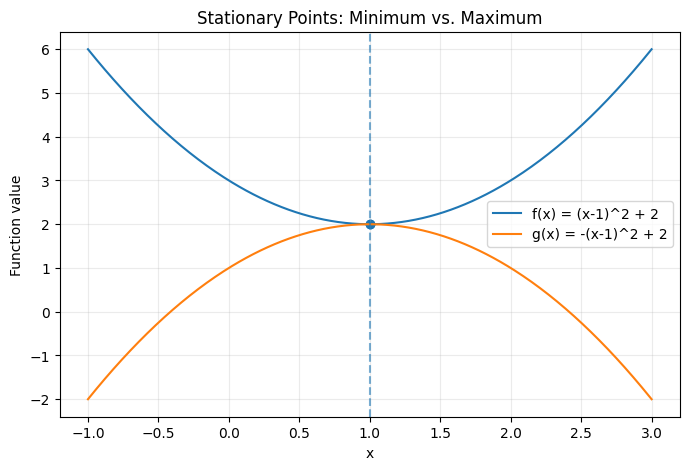

In [13]:
x = np.linspace(-1, 3, 400)

plt.figure(figsize=(8, 5))

plt.plot(x, f(x), label="f(x) = (x-1)^2 + 2")
plt.plot(x, g(x), label="g(x) = -(x-1)^2 + 2")

plt.scatter([1, 1], [f(1), g(1)])
plt.axvline(1, linestyle="--", alpha=0.6)

plt.xlabel("x")
plt.ylabel("Function value")
plt.title("Stationary Points: Minimum vs. Maximum")
plt.legend()
plt.grid(alpha=0.25)

plt.show()

The output shows the the functions satify the nessecary conditions. However their second derviatives have different signs.
The nearby function values and the graph confirm that having a first derivative being zero is required at an interior local minimum that has a valid derivative.

The convex is important to optimization because every local min of the xoncex function is also a global min.
For a two derivative function of a single bariable the useful condition for convexity is
F''(x) >= 0 throughout the domain then the function is strictly convex and can have no more than one min.

In [14]:
def h(x):
    return x**2 + 4*x + 7

def h_prime(x):
    return 2*x + 4

def h_second(x):
    return 2 + 0*x

# Theoretical global minimizer
x_global = -2.0

# Sample points for numerical verification
sample_x = np.linspace(-8, 4, 1001)
sample_values = h(sample_x)

print("Candidate minimizer x* =", x_global)
print("h'(x*) =", h_prime(x_global))
print("h''(x*) =", h_second(x_global))
print("h(x*) =", h(x_global))

print("Smallest sampled h(x) =", sample_values.min())

print(
    "Sample point attaining smallest value =",
    sample_x[np.argmin(sample_values)]
)

print(
    "Are all sampled values >= h(x*)?",
    np.all(sample_values >= h(x_global) - 1e-12)
)

Candidate minimizer x* = -2.0
h'(x*) = 0.0
h''(x*) = 2.0
h(x*) = 3.0
Smallest sampled h(x) = 3.0
Sample point attaining smallest value = -2.0
Are all sampled values >= h(x*)? True


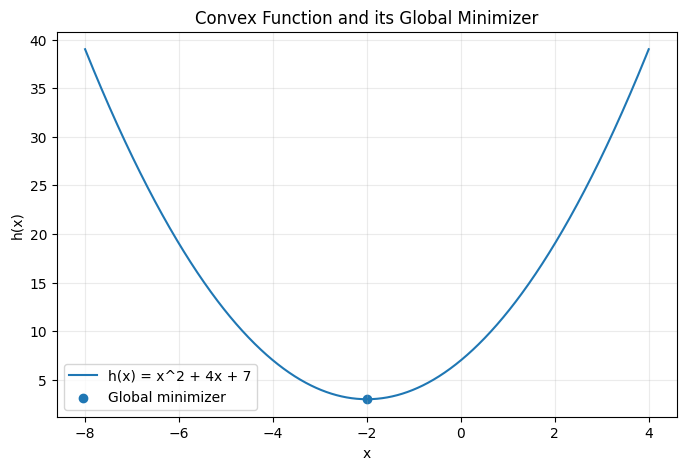

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    sample_x,
    sample_values,
    label="h(x) = x^2 + 4x + 7"
)

plt.scatter(
    [x_global],
    [h(x_global)],
    label="Global minimizer"
)

plt.xlabel("x")
plt.ylabel("h(x)")
plt.title("Convex Function and its Global Minimizer")
plt.legend()
plt.grid(alpha=0.25)

plt.show()

The second derivative is greater than 0 which confirms the graph is strictly convex the stationary point occurses at x = -2

Gradiant descent is an interative optimizing algorithm that tries to move to the minimum of a function

In [16]:
learning_rate = 0.20
x_current = 6.0
iterations = 20

history_x = [x_current]
history_h = [h(x_current)]

for k in range(iterations):

    # This the derivative at the current point
    gradient = h_prime(x_current)

    # Gradient descent update
    x_current = x_current - learning_rate * gradient

    # Store the new results
    history_x.append(x_current)
    history_h.append(h(x_current))

history_x = np.array(history_x)
history_h = np.array(history_h)

print("Starting point:", history_x[0])
print("Final point:", history_x[-1])
print("Exact minimizer:", x_global)

print(
    "Distance from exact minimizer:",
    abs(history_x[-1] - x_global)
)

print("Starting function value:", history_h[0])
print("Final function value:", history_h[-1])

print(
    "Function values never increased?",
    np.all(np.diff(history_h) <= 1e-12)
)

print("\nFirst six iterations:")

for k in range(6):
    print(
        f"k={k:2d}: "
        f"x={history_x[k]: .6f}, "
        f"h(x)={history_h[k]: .6f}"
    )



Starting point: 6.0
Final point: -1.999707507324795
Exact minimizer: -2.0
Distance from exact minimizer: 0.0002924926752050361
Starting function value: 67.0
Final function value: 3.000000085551965
Function values never increased? True

First six iterations:
k= 0: x= 6.000000, h(x)= 67.000000
k= 1: x= 2.800000, h(x)= 26.040000
k= 2: x= 0.880000, h(x)= 11.294400
k= 3: x=-0.272000, h(x)= 5.985984
k= 4: x=-0.963200, h(x)= 4.074954
k= 5: x=-1.377920, h(x)= 3.386984


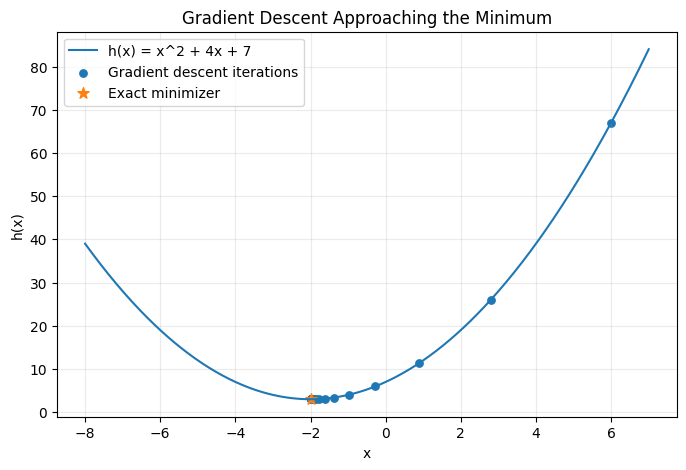

In [17]:
plot_x = np.linspace(-8, 7, 500)

plt.figure(figsize=(8, 5))

plt.plot(
    plot_x,
    h(plot_x),
    label="h(x) = x^2 + 4x + 7"
)

plt.scatter(
    history_x,
    history_h,
    s=28,
    label="Gradient descent iterations"
)

plt.scatter(
    [x_global],
    [h(x_global)],
    s=70,
    marker="*",
    label="Exact minimizer"
)

plt.xlabel("x")
plt.ylabel("h(x)")
plt.title("Gradient Descent Approaching the Minimum")
plt.legend()
plt.grid(alpha=0.25)

plt.show()

Gradient descent begins at x = 6 which is not the true min. At each interation the calculated derivative shows movement in the direction opposite to the ghradient. Each iteration gets progressively closer to the min while the function values decrease

Alpha is what controls trhe size of each descent step. Small Alphas become expension and large alpha's over shoot.

In [18]:
def gradient_descent(alpha, x0=6.0, n=15):
    xs = [x0]
    x = x0

    for _ in range(n):
        x = x - alpha * h_prime(x)
        xs.append(x)

    return np.array(xs)


rates = [0.05, 0.20, 1.10]

for alpha in rates:
    xs = gradient_descent(alpha)

    print(
        f"alpha={alpha:.2f}: "
        f"final x={xs[-1]: .6f}, "
        f"final h(x)={h(xs[-1]): .6f}"
    )

alpha=0.05: final x=-0.352871, final h(x)= 5.713034
alpha=0.20: final x=-1.996239, final h(x)= 3.000014
alpha=1.10: final x=-125.256173, final h(x)= 15195.084083


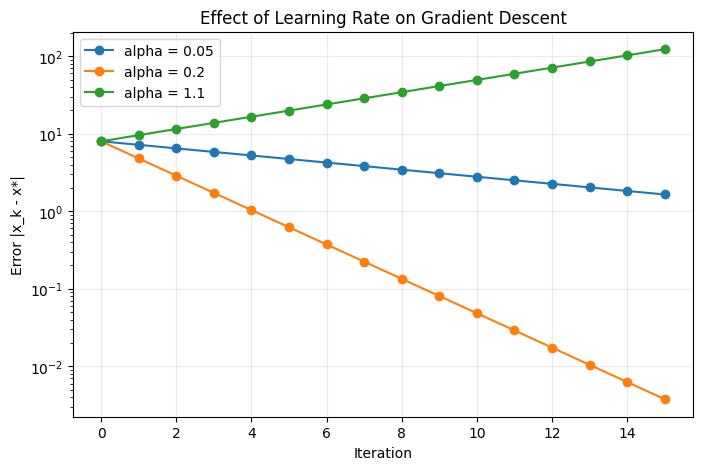

In [19]:
plt.figure(figsize=(8, 5))

for alpha in rates:
    xs = gradient_descent(alpha)

    plt.plot(
        range(len(xs)),
        np.abs(xs - x_global),
        marker="o",
        label=f"alpha = {alpha}"
    )

plt.yscale("log")

plt.xlabel("Iteration")
plt.ylabel("Error |x_k - x*|")
plt.title("Effect of Learning Rate on Gradient Descent")
plt.legend()
plt.grid(alpha=0.25)

plt.show()

The comparison of learning rate shows the choice of alpha has a major effect when it comes to gradient deswcent.

With an alpha of .05, the algorithm has a relatively slow approach to the min.


However, with alpha being .2 the error decreases quicker and the interation approaches x=-2 faster

With an Alpha of 1.10, the learning rate is too large for this function. It moves away from the min instead of approaching like we want.

This proves that gradient descent requires appropriate learning rates in order for convergence.



# Reflection

This section connects the math theory of omptimization with an optimization algorithm.

A first derivative that is 0 identifies a static point, though that isn't proof that the point is a min. Just that it's an extrema. The second derivative test is what fundamentallyt provides sufficient context for mins and maxes.

The convex of a function gives stronger results because it is also a global extrema.
Gradient descent shows how computers can approximate that same value with repeated updates and calculatiuons. Step size is important. too large and the value is meaningless too small and it takes too much processing power.



---

# Submission Checklist

 My name and course information are included.
 All Python cells run without errors.
 I demonstrated necessary and sufficient conditions for local minimizers.
I demonstrated convexity and global minimizers.
 I demonstrated gradient descent.
 Each concept includes an explanation, executable code, verification, and interpretation.
 My graphs contain readable titles, axis labels, and legends.
I personalized values, comments, examples, or reflection where appropriate.
The notebook is saved from Google Colab directly to GitHub.
 The **Open in Colab** button is visible and works from GitHub.